| Факультет | Программной Инженерии и Компьютерной Техники |
| --- | --- |
| Направление подготовки (специальность) | СППО |
| Дисциплина | Системы искусственного интеллекта |

| Выполнил студент: | Чжун Цзяцзюнь 407959 |
| --- | --- |
| Группа: | P3310 |
| Преподаватель: | Болдырева Елена Александровна (157150) |

## Титульный лист

Министерство науки и высшего образования Российской Федерации

федеральное государственное автономное образовательное учреждение высшего образования

“НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ ИТМО”

Лабораторная работа 4

ОТЧЕТ 

г. Санкт-Петербург

2026

## Содержание

1. [ЦЕЛЬ РАБОТЫ И ТЕОРИЯ](#section-1)
2. [ОПИСАТЕЛЬНАЯ СТАТИСТИКА WINE](#section-2)
3. [ОПИСАТЕЛЬНАЯ СТАТИСТИКА DIABETES](#section-3)
4. [РАЗБИЕНИЕ И ПРЕДОБРАБОТКА](#section-4)
5. [ВАЛИДАЦИЯ: КЛАССИФИКАЦИЯ](#section-5)
6. [ВАЛИДАЦИЯ: РЕГРЕССИЯ](#section-6)
7. [ТЕСТ: КЛАССИФИКАЦИЯ](#section-7)
8. [ТЕСТ: РЕГРЕССИЯ](#section-8)
9. [РЕАЛИЗАЦИЯ КЛАССА KNN](#section-9)
10. [САМОСТОЯТЕЛЬНЫЕ МЕТРИКИ](#section-10)
11. [ВЫВОДЫ](#section-11)

<a id="section-1"></a>

## 1. ЦЕЛЬ РАБОТЫ И ТЕОРИЯ

Метод k-ближайших соседей (kNN). Цель: самостоятельно реализовать классификацию и регрессию, исследовать влияние числа соседей и расстояния и проверить качество при разбиении без утечки данных.

kNN является непараметрическим ленивым методом: fit сохраняет обучающие объекты, а predict вычисляет расстояния до них. Для классификации используется большинство голосов k соседей, для регрессии - среднее их целевых значений.

$$
d_2(x,u)=\sqrt{\sum_{j=1}^{d}(x_j-u_j)^2},\quad d_1(x,u)=\sum_{j=1}^{d}|x_j-u_j|
$$

$$
d_\infty(x,u)=\max_j|x_j-u_j|,\quad \hat y_{\mathrm{regr}}=\frac1k\sum_{i\in N_k(x)}y_i
$$

При равенстве голосов выбирается класс с меньшей суммой расстояний до его соседей. Если равны и суммы, выбирается меньшая числовая метка. Равные расстояния при отборе k соседей разрешаются исходным порядком объектов train (стабильная сортировка).

$$
\mathrm{accuracy}=\frac{\sum_c TP_c}{N},\qquad P_c=\frac{TP_c}{TP_c+FP_c}
$$

$$
R_c=\frac{TP_c}{TP_c+FN_c},\qquad F1_c=\frac{2P_cR_c}{P_c+R_c}
$$

Macro precision, recall и F1 - среднее соответствующих показателей по классам. Сначала вычисляется F1 каждого класса, затем берётся среднее, F1 не вычисляется из уже усреднённых precision и recall. При нулевом знаменателе показатель класса принят равным нулю.

$$
\mathrm{MAE}=\frac1N\sum_{i=1}^N|y_i-\hat y_i|,\quad \mathrm{MSE}=\frac1N\sum_{i=1}^N(y_i-\hat y_i)^2
$$

$$
R^2=1-\frac{\sum_{i=1}^N(y_i-\hat y_i)^2}{\sum_{i=1}^N(y_i-\bar y)^2}
$$

В R² среднее ȳ относится к оцениваемому набору. Для постоянного y знаменатель равен нулю: реализация возвращает NaN. В Wine и Diabetes этой ситуации нет. Масштабирование необходимо, так как признаки с большим численным разбросом иначе доминируют в расстоянии.

<a id="section-2"></a>

## 2. ОПИСАТЕЛЬНАЯ СТАТИСТИКА WINE

Источник: sklearn.datasets.load_wine(). 178 объектов, 13 числовых химических признаков, три класса вина: 59, 71 и 48 объектов. Пропусков и полных дубликатов нет. Классы обозначены 0, 1 и 2, их номера не задают порядок качества вина.

| Признак | Среднее | SD | Мин. | Q1 | Медиана | Q3 | Макс. |
| --- | --- | --- | --- | --- | --- | --- | --- |
| alcohol | 13.00 | 0.81 | 11.03 | 12.36 | 13.05 | 13.68 | 14.83 |
| malic_acid | 2.34 | 1.12 | 0.74 | 1.60 | 1.86 | 3.08 | 5.80 |
| ash | 2.37 | 0.27 | 1.36 | 2.21 | 2.36 | 2.56 | 3.23 |
| alcalinity | 19.49 | 3.34 | 10.60 | 17.20 | 19.50 | 21.50 | 30.00 |
| magnesium | 99.74 | 14.28 | 70.00 | 88.00 | 98.00 | 107.00 | 162.00 |
| total_phenols | 2.30 | 0.63 | 0.98 | 1.74 | 2.35 | 2.80 | 3.88 |
| flavanoids | 2.03 | 1.00 | 0.34 | 1.21 | 2.13 | 2.88 | 5.08 |
| nonflav. phenols | 0.36 | 0.12 | 0.13 | 0.27 | 0.34 | 0.44 | 0.66 |
| proanthocyanins | 1.59 | 0.57 | 0.41 | 1.25 | 1.56 | 1.95 | 3.58 |
| color_intensity | 5.06 | 2.32 | 1.28 | 3.22 | 4.69 | 6.20 | 13.00 |
| hue | 0.96 | 0.23 | 0.48 | 0.78 | 0.96 | 1.12 | 1.71 |
| OD280/OD315 | 2.61 | 0.71 | 1.27 | 1.94 | 2.78 | 3.17 | 4.00 |
| proline | 746.89 | 314.91 | 278.00 | 500.50 | 673.50 | 985.00 | 1680.00 |

Таблица: статистика исходных данных, SD рассчитано с ddof=1. Число наблюдений одинаково для всех признаков. Полные имена и точные значения сохранены в CSV. 

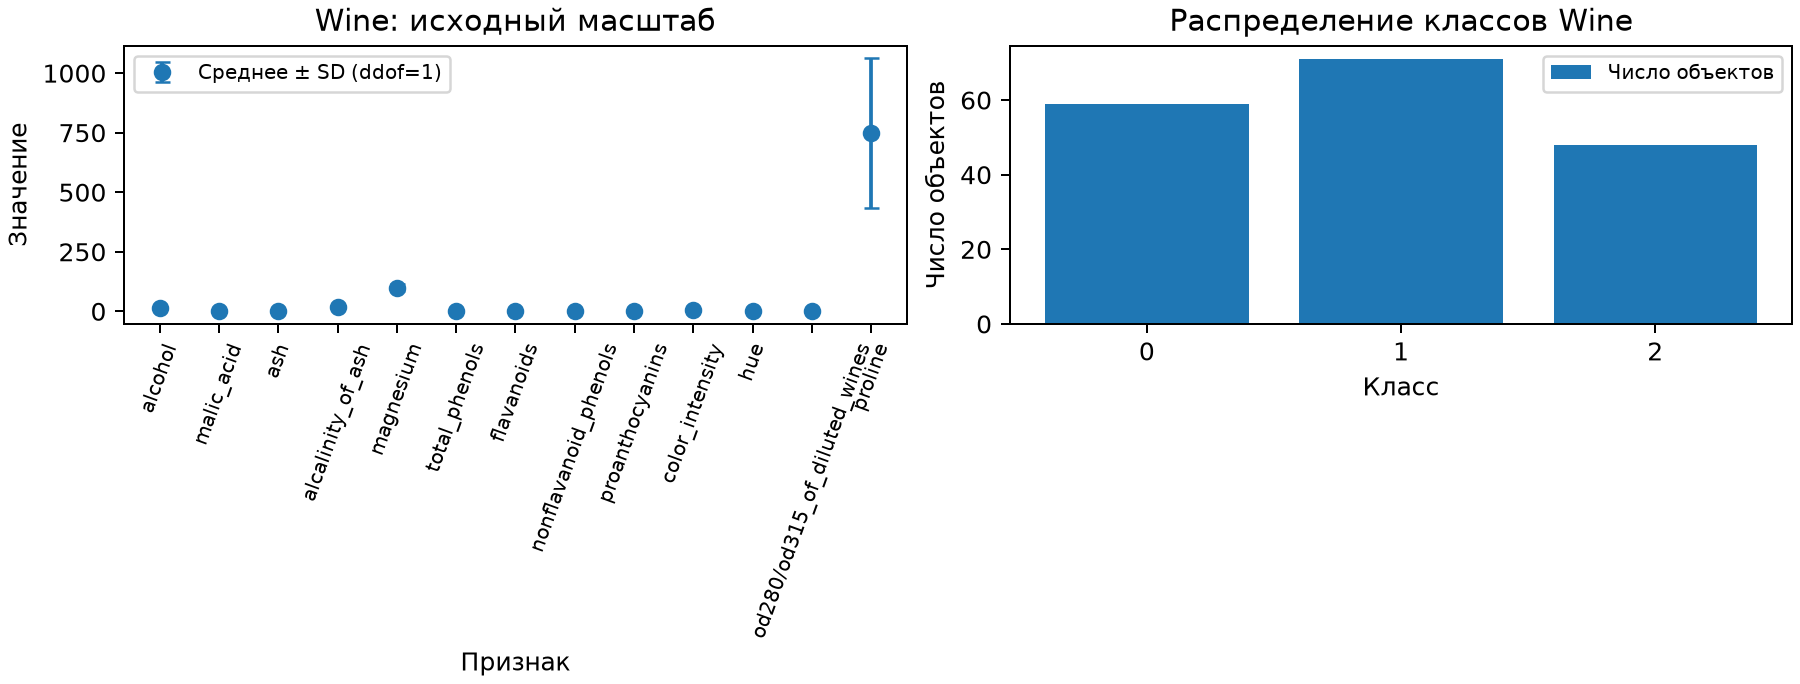

Рисунок 1. Масштаб признаков и распределение целевой переменной.

Разброс proline (SD = 314,91) намного больше, чем у hue (SD = 0,23). Без стандартизации вклад proline в расстояние был бы несоразмерно большим.

<a id="section-3"></a>

## 3. ОПИСАТЕЛЬНАЯ СТАТИСТИКА DIABETES

Источник: sklearn.datasets.load_diabetes(scaled=False). 442 пациента, 10 исходных числовых признаков, цель - количественный показатель прогрессирования заболевания через год. Пропусков и полных дубликатов нет. age - возраст, sex - код пола 1/2, bmi - индекс массы тела, bp - среднее давление, s1–s6 - показатели сыворотки крови.

| Признак | Среднее | SD | Мин. | Q1 | Медиана | Q3 | Макс. |
| --- | --- | --- | --- | --- | --- | --- | --- |
| age | 48.52 | 13.11 | 19.00 | 38.25 | 50.00 | 59.00 | 79.00 |
| sex | 1.47 | 0.50 | 1.00 | 1.00 | 1.00 | 2.00 | 2.00 |
| bmi | 26.38 | 4.42 | 18.00 | 23.20 | 25.70 | 29.27 | 42.20 |
| bp | 94.65 | 13.83 | 62.00 | 84.00 | 93.00 | 105.00 | 133.00 |
| s1 | 189.14 | 34.61 | 97.00 | 164.25 | 186.00 | 209.75 | 301.00 |
| s2 | 115.44 | 30.41 | 41.60 | 96.05 | 113.00 | 134.50 | 242.40 |
| s3 | 49.79 | 12.93 | 22.00 | 40.25 | 48.00 | 57.75 | 99.00 |
| s4 | 4.07 | 1.29 | 2.00 | 3.00 | 4.00 | 5.00 | 9.09 |
| s5 | 4.64 | 0.52 | 3.26 | 4.28 | 4.62 | 5.00 | 6.11 |
| s6 | 91.26 | 11.50 | 58.00 | 83.25 | 91.00 | 98.00 | 124.00 |
| target | 152.13 | 77.09 | 25.00 | 87.00 | 140.50 | 211.50 | 346.00 |

Таблица: статистика исходных данных, SD рассчитано с ddof=1. Число наблюдений одинаково для всех признаков. Полные имена и точные значения сохранены в CSV. 

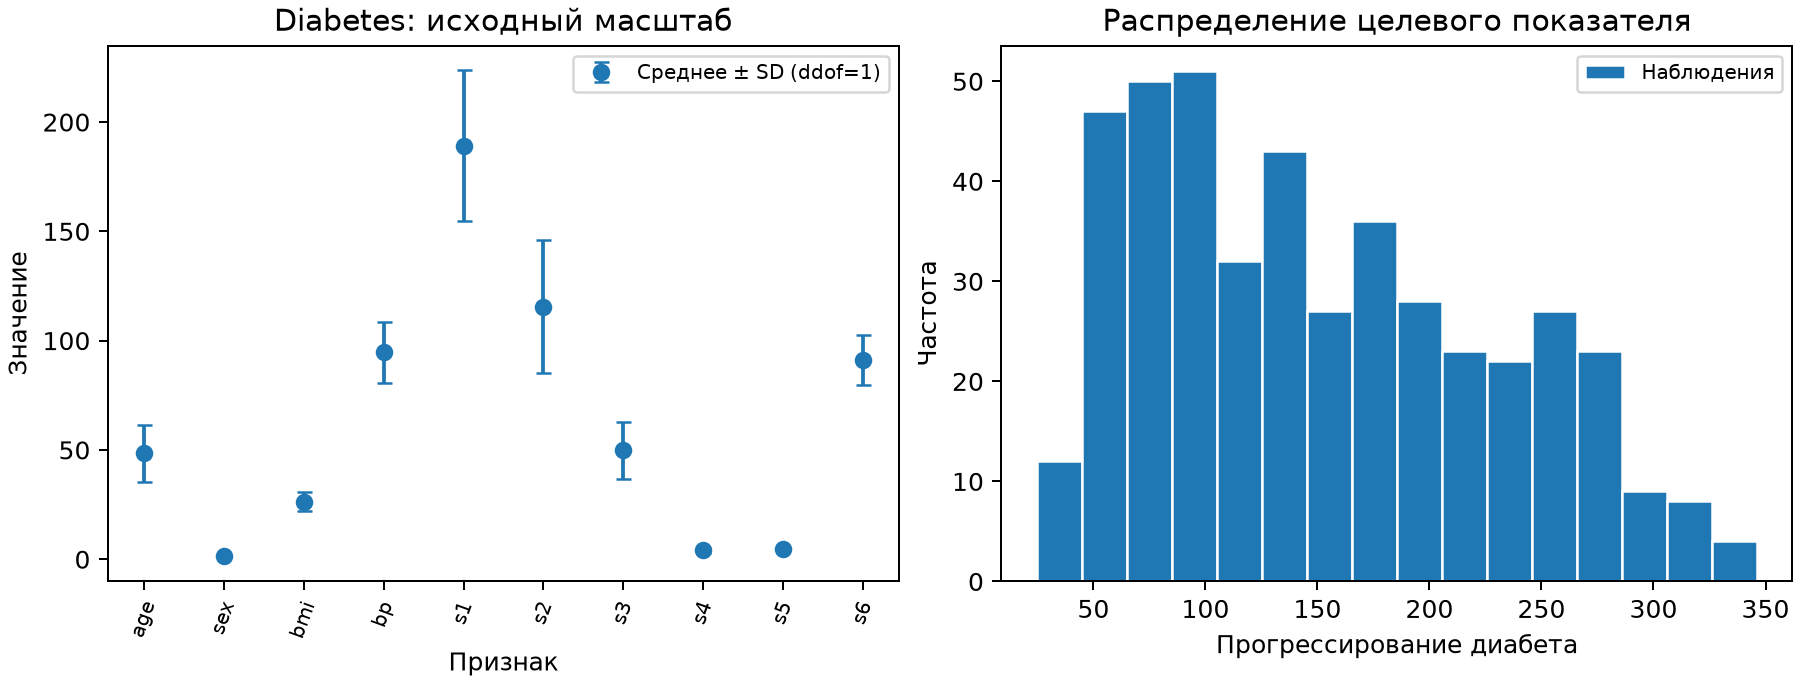

Рисунок 2. Масштаб признаков и распределение целевой переменной.

Вызов scaled=False исключает предварительное масштабирование по всему набору. Код пола уже числовой, дополнительное кодирование не требуется, стандартизация применяется ко всем десяти признакам, цель не масштабируется.

<a id="section-4"></a>

## 4. РАЗБИЕНИЕ И ПРЕДОБРАБОТКА

Зафиксирован random_state = 42. Сначала 40 % объектов выделяются во временный набор, затем он делится пополам на validation и test. Для Wine оба разбиения стратифицированы. Из-за округления размеров доли близки к 60/20/20.

| Набор | Train | Validation | Test | Всего |
| --- | --- | --- | --- | --- |
| Wine | 106 | 36 | 36 | 178 |
| Diabetes | 265 | 88 | 89 | 442 |

| Класс Wine | Train | Validation | Test | Всего |
| --- | --- | --- | --- | --- |
| 0 | 35 | 12 | 12 | 59 |
| 1 | 42 | 14 | 15 | 71 |
| 2 | 29 | 10 | 9 | 48 |

$$
z_j=\frac{x_j-\mu_{\mathrm{train},j}}{\sigma_{\mathrm{train},j}},\quad ddof=0
$$

Среднее и стандартное отклонение вычисляются исключительно по train, затем неизменно применяются к validation и test. Для постоянного признака делитель заменяется на 1. В этих двух наборах постоянных признаков нет. 

Например, для Wine на train: μ(proline) = 755,0283, σ(proline) = 314,3256. Для Diabetes: μ(bmi) = 26,6113, σ(bmi) = 4,4416. 

Для каждой задачи проверены 4 значения k (3, 5, 10, 15) и 3 расстояния, всего 12 конфигураций. Wine: максимизируется macro F1, Diabetes: минимизируется MSE. При равенстве главного показателя выбирается меньшее k, затем расстояние по порядку: евклидово, манхэттенское, Чебышёва.

После выбора конфигурации модель сохраняет только исходный train, объединения train и validation нет. Для выбранной модели predict вызывается на test один раз. Тест не участвует в подборе параметров. Реализованы собственные KNN, матрица ошибок и метрики, sklearn используется только для загрузки данных и train_test_split.

<a id="section-5"></a>

## 5. ВАЛИДАЦИЯ: КЛАССИФИКАЦИЯ

| Расстояние | k | Accuracy | P macro | R macro | F1 macro |
| --- | --- | --- | --- | --- | --- |
| Евклидово | 3 | 0.9167 | 0.9221 | 0.9286 | 0.9185 |
| Евклидово | 5 | 0.9444 | 0.9441 | 0.9524 | 0.9452 |
| Евклидово | 10 | 0.9444 | 0.9441 | 0.9524 | 0.9452 |
| Евклидово | 15 | 0.9722 | 0.9744 | 0.9762 | 0.9743 |
| Манхэттенское | 3 | 0.9167 | 0.9221 | 0.9286 | 0.9185 |
| Манхэттенское | 5 | 0.9444 | 0.9441 | 0.9524 | 0.9452 |
| Манхэттенское | 10 | 0.9444 | 0.9441 | 0.9524 | 0.9452 |
| Манхэттенское | 15 | 0.9444 | 0.9524 | 0.9524 | 0.9487 |
| Чебышёва | 3 | 0.8889 | 0.8968 | 0.9048 | 0.8885 |
| Чебышёва | 5 | 0.8889 | 0.8913 | 0.8952 | 0.8897 |
| Чебышёва | 10 | 0.8611 | 0.8603 | 0.8675 | 0.8629 |
| Чебышёва | 15 | 0.8333 | 0.8333 | 0.8437 | 0.8347 |

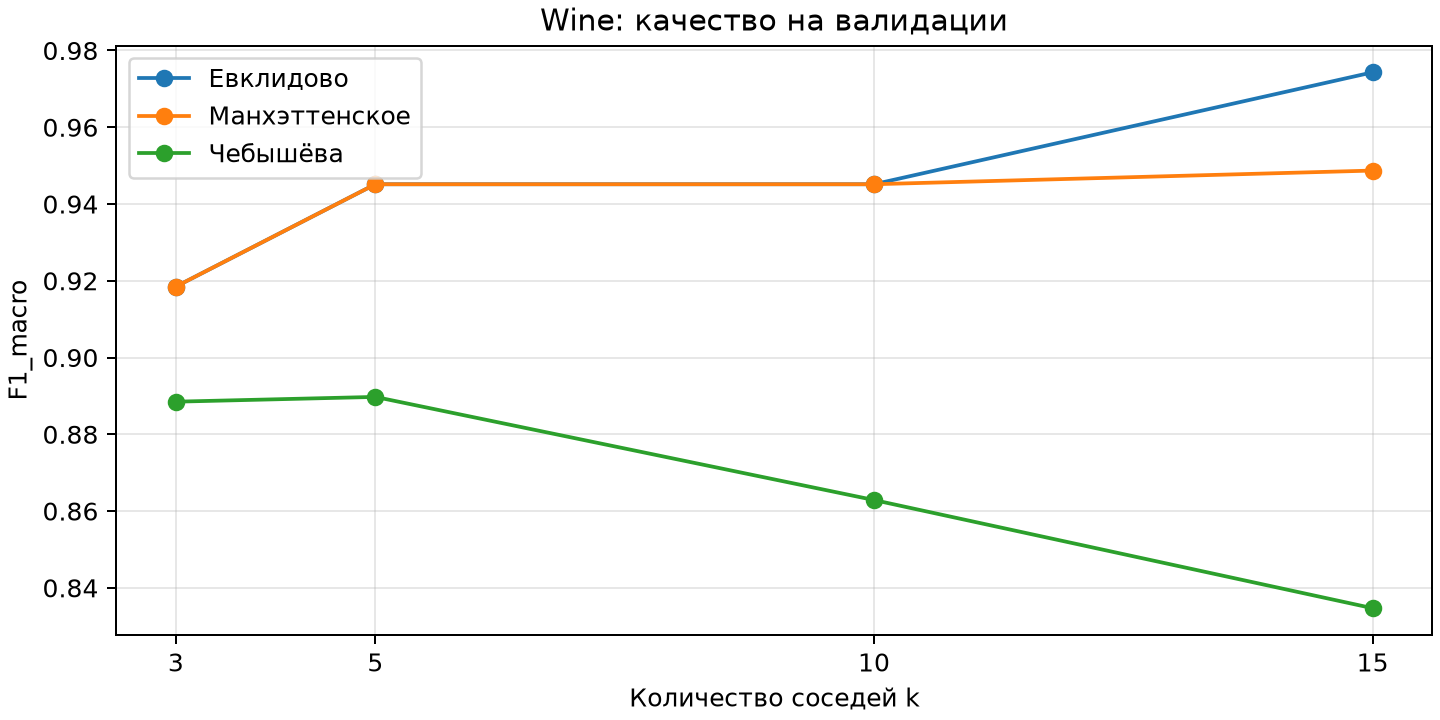

Рисунок 3. Зависимость качества от k для трёх расстояний.

Лучший результат: k = 15, евклидово расстояние, macro F1 = 0,9743. Для L2 увеличение k улучшает качество, для L∞ качество при k = 15 падает до 0,8347. Усреднение соседей не гарантирует улучшения при любой метрике.

<a id="section-6"></a>

## 6. ВАЛИДАЦИЯ: РЕГРЕССИЯ

| Расстояние | k | MAE | MSE | R² |
| --- | --- | --- | --- | --- |
| Евклидово | 3 | 42.5720 | 3224.7790 | 0.4406 |
| Евклидово | 5 | 45.4523 | 3330.0986 | 0.4224 |
| Евклидово | 10 | 44.4716 | 2944.0408 | 0.4893 |
| Евклидово | 15 | 45.7265 | 3122.2894 | 0.4584 |
| Манхэттенское | 3 | 46.2008 | 3420.3699 | 0.4067 |
| Манхэттенское | 5 | 45.7750 | 3378.4523 | 0.4140 |
| Манхэттенское | 10 | 46.6045 | 3340.7277 | 0.4205 |
| Манхэттенское | 15 | 47.2492 | 3329.6589 | 0.4224 |
| Чебышёва | 3 | 44.7045 | 3161.4419 | 0.4516 |
| Чебышёва | 5 | 44.3568 | 2932.8132 | 0.4913 |
| Чебышёва | 10 | 44.3648 | 2920.7997 | 0.4933 |
| Чебышёва | 15 | 44.6121 | 2915.4694 | 0.4943 |

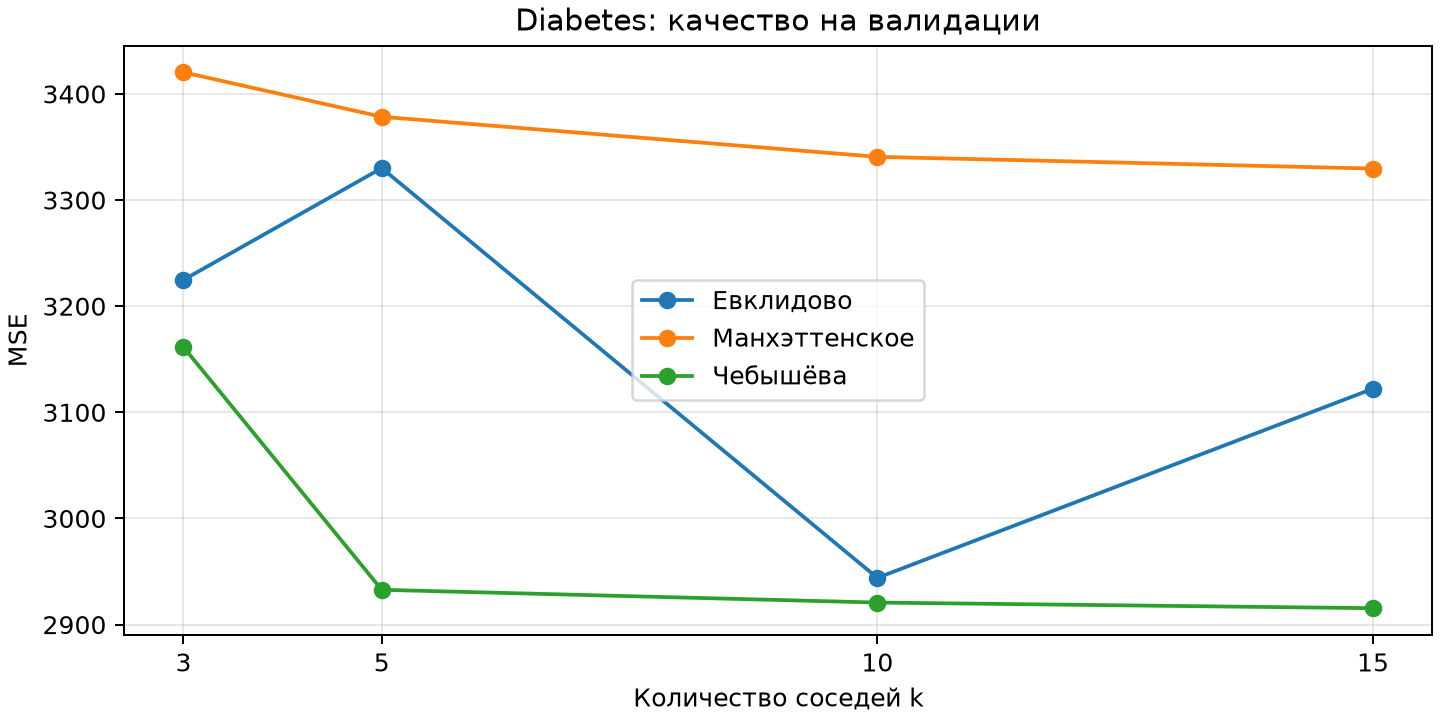

Рисунок 4. Зависимость качества от k для трёх расстояний.

Лучший результат по MSE: k = 15, расстояние Чебышёва, MSE = 2915,4694, R² = 0,4943. Различие с k = 10 для этой метрики небольшое: 5,3303 единицы MSE. Минимальная MAE (42,5720) достигается при L2 и k = 3, но параметр выбирается по заранее принятой MSE.

<a id="section-7"></a>

## 7. ТЕСТ: КЛАССИФИКАЦИЯ

Финальная конфигурация Wine: k = 15, евклидово расстояние, обучение на 106 объектах, тест на 36 объектах.

| Accuracy | Precision macro | Recall macro | F1 macro |
| --- | --- | --- | --- |
| 0.9722 | 0.9667 | 0.9778 | 0.9710 |

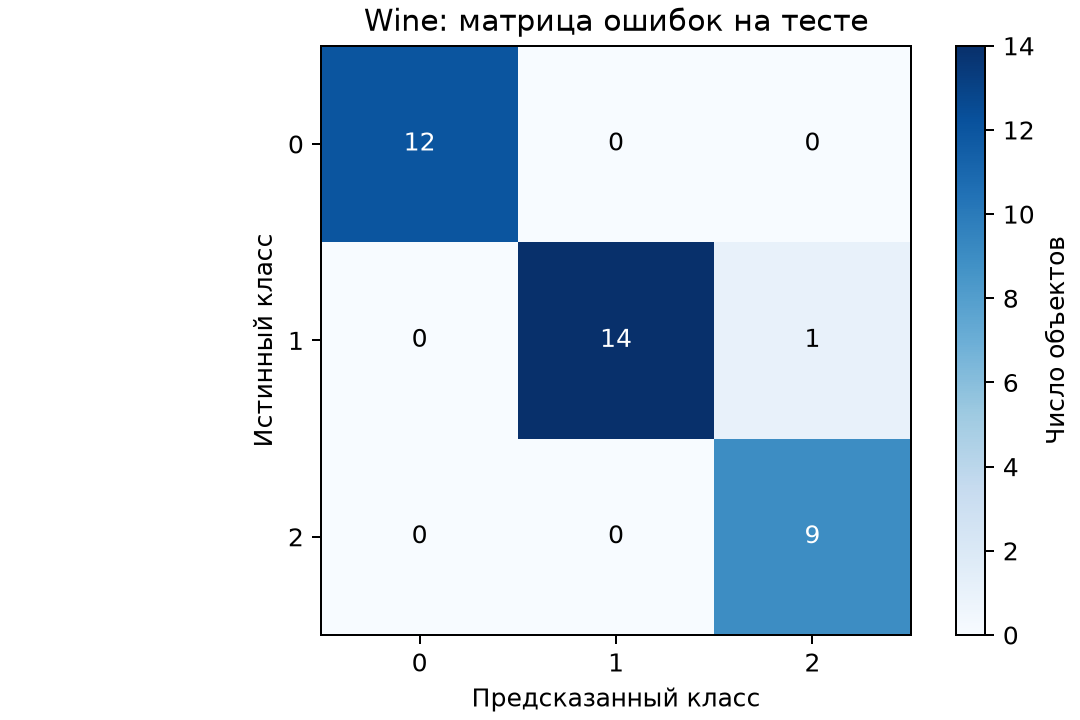

Рисунок 5. Строки - истинный класс, столбцы - предсказанный.

Верно классифицированы 35 из 36 объектов. Единственная ошибка: один объект истинного класса 1 отнесён к классу 2. Все 12 объектов класса 0 и все 9 объектов класса 2 распознаны верно. Для класса 2 precision = 9/10, а recall = 9/9.

Тестовая macro F1 = 0,9710 близка к валидационной 0,9743.

<a id="section-8"></a>

## 8. ТЕСТ: РЕГРЕССИЯ

Финальная конфигурация Diabetes: k = 15, расстояние Чебышёва, обучение на 265 объектах, тест на 89 объектах.

| MAE | MSE | R² |
| --- | --- | --- |
| 46.5213 | 3175.5054 | 0.4510 |

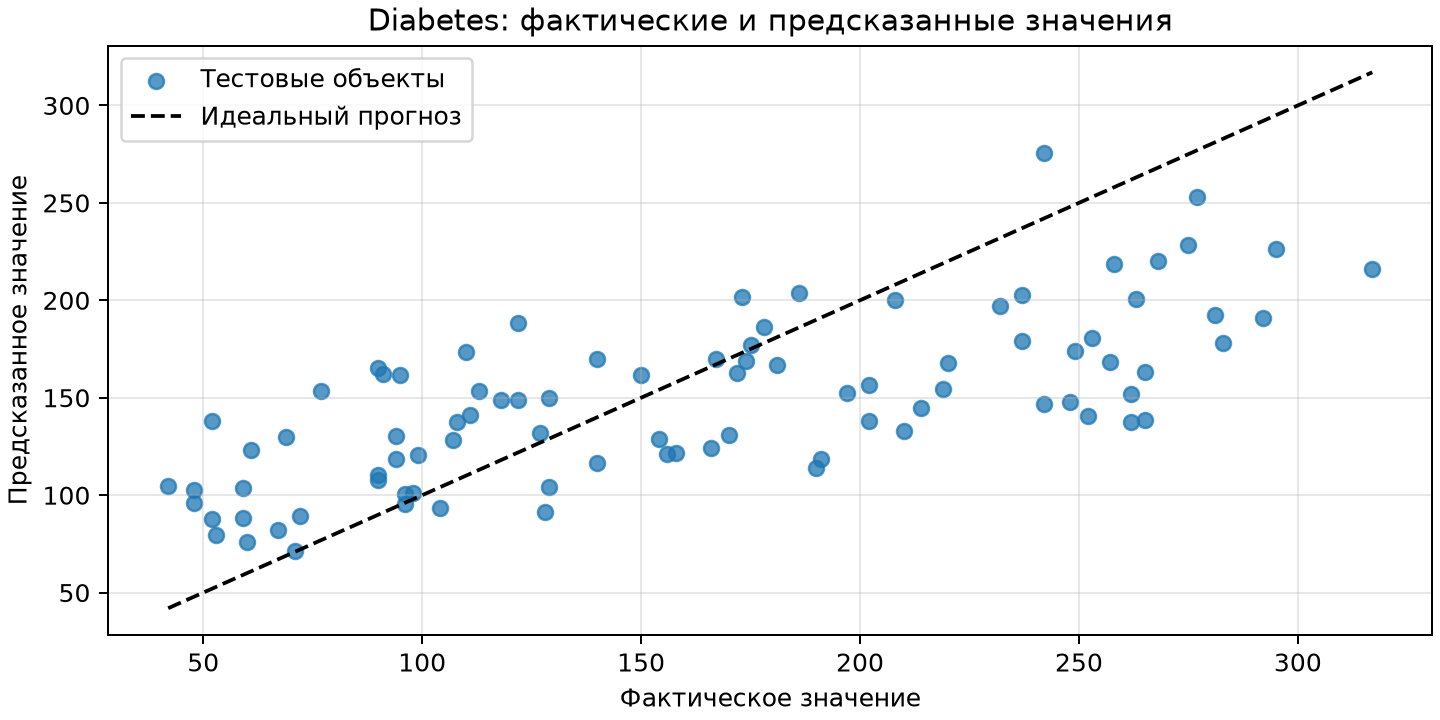

Рисунок 6. Сопоставление фактических значений и прогнозов на тесте.

Средняя абсолютная ошибка составляет 46,5213 единицы целевого показателя. R² = 0,4510 означает снижение суммы квадратов ошибок примерно на 45,10 % относительно постоянного прогноза, равного среднему фактических значений теста. 

Прогнозы усредняются по соседям: на графике заметно сглаживание крайних значений. MSE теста (3175,5054) выше валидационной MSE (2915,4694), выборка невелика, а усреднение 15 наблюдений ограничивает возможность точно воспроизводить крайние значения.

<a id="section-9"></a>

## 9. РЕАЛИЗАЦИЯ КЛАССА KNN

Полный исходный код. Комментарии поясняют правило выбора соседей и голосования.

In [ ]:
"""kNN: fit сохраняет данные, predict находит соседей и формирует ответ."""
import numpy as np


class KNN:
    def __init__(self, k=5, task="classification", metric="euclidean"):
        if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError("k должен быть положительным целым.")
        if task not in ("classification", "regression"):
            raise ValueError("task: classification или regression.")
        if metric not in ("euclidean", "manhattan", "chebyshev"):
            raise ValueError("Неизвестная метрика расстояния.")
        self.k, self.task, self.metric = k, task, metric

    def fit(self, x, y):
        x, y = np.asarray(x, dtype=float), np.asarray(y)
        if x.ndim != 2 or x.shape[1] == 0 or y.ndim != 1 or len(x) != len(y):
            raise ValueError("x: матрица признаков, y: числовой вектор той же длины.")
        if self.k > len(x) or not np.isfinite(x).all() or not np.isfinite(y).all():
            raise ValueError("Нужно не менее k объектов и только конечные значения.")
        self.x, self.y = x.copy(), y.copy()
        return self

    def predict(self, x):
        if not hasattr(self, "x"):
            raise ValueError("Сначала вызовите fit.")
        x = np.asarray(x, dtype=float)
        if x.ndim != 2 or x.shape[1] != self.x.shape[1] or not np.isfinite(x).all():
            raise ValueError("Нужны те же признаки, что в train, и конечные значения.")
        predictions = []
        for row in x:
            difference = np.abs(self.x - row)
            if self.metric == "euclidean":
                distance = np.sqrt((difference ** 2).sum(axis=1))
            elif self.metric == "manhattan":
                distance = difference.sum(axis=1)
            else:
                distance = difference.max(axis=1)
            # При равных расстояниях сохраняем порядок train, включая границу k.
            nearest = np.argsort(distance, kind="stable")[:self.k]
            values = self.y[nearest]
            if self.task == "regression":
                prediction = values.mean()
            else:
                labels, groups = np.unique(values, return_inverse=True)
                votes = np.bincount(groups)
                totals = np.bincount(groups, weights=distance[nearest])
                # Сначала число голосов, затем сумма расстояний и меньшая метка.
                winner = min(range(len(labels)), key=lambda i: (-votes[i], totals[i], labels[i]))
                prediction = labels[winner]
            predictions.append(prediction)
        return np.asarray(predictions)

: 

<a id="section-10"></a>

## 10. САМОСТОЯТЕЛЬНЫЕ МЕТРИКИ

Полный код собственных метрик. Строки матрицы ошибок соответствуют истинным классам, столбцы - предсказанным.

In [ ]:
"""Собственные метрики классификации и регрессии без sklearn.metrics."""
import numpy as np


def paired_values(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    if actual.ndim != 1 or actual.shape != predicted.shape or not actual.size:
        raise ValueError("Нужны непустые одномерные массивы одинаковой длины.")
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Значения должны быть конечными.")
    return actual, predicted


def confusion_matrix(actual, predicted, labels):
    actual, predicted = paired_values(actual, predicted)
    labels = np.asarray(labels)
    if labels.ndim != 1 or len(np.unique(labels)) != len(labels):
        raise ValueError("Метки: одномерный массив без повторов.")
    if not np.isin(actual, labels).all() or not np.isin(predicted, labels).all():
        raise ValueError("Список классов должен содержать все истинные и предсказанные метки.")
    return np.array([[np.sum((actual == a) & (predicted == p))
                      for p in labels] for a in labels])


def classification_metrics(actual, predicted):
    actual, predicted = paired_values(actual, predicted)
    matrix = confusion_matrix(actual, predicted, np.union1d(actual, predicted))
    tp = np.diag(matrix)
    # При нулевом знаменателе метрика класса равна 0.
    precision = tp / np.maximum(matrix.sum(axis=0), 1)
    recall = tp / np.maximum(matrix.sum(axis=1), 1)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros_like(precision), where=(precision + recall) != 0)
    return {"accuracy": float(tp.sum() / matrix.sum()),
            "precision_macro": float(precision.mean()),
            "recall_macro": float(recall.mean()), "F1_macro": float(f1.mean())}


def regression_metrics(actual, predicted):
    actual, predicted = paired_values(actual, predicted)
    error = actual.astype(float) - predicted
    mse = float(np.mean(error ** 2))
    variance = float(np.mean((actual - actual.mean()) ** 2))
    return {"MAE": float(np.mean(np.abs(error))), "MSE": mse,
            "R2": 1 - mse / variance if variance else float("nan")}

<a id="section-11"></a>

## 11. ВЫВОДЫ

Реализованы классификация и регрессия kNN, три расстояния и собственные метрики. Проверены все 24 конфигурации. Wine лучше классифицируется при k = 15 и L2 (тестовая accuracy 0,9722), Diabetes лучше по валидационной MSE при k = 15 и L∞ (тестовое R² 0,4510). Единой лучшей метрики для обеих задач не найдено.

Большое k снижает чувствительность к отдельным наблюдениям, но может смешивать классы или чрезмерно сглаживать регрессию. На Wine расстояние L∞ ухудшает качество при росте k, на Diabetes оно даёт лучший результат. 

## Приложение — воспроизведение / 附录：运行并核对

新增演示单元：使用上文报告中的 KNN 和指标代码，复现原划分、24 组验证实验和最终测试；不调用会覆盖 output 的脚本，不写入实验文件。复现不用于再次按测试集选参。

Ячейки ниже воспроизводят исходный эксперимент в памяти и проверяют соответствие сохранённым результатам. Рисунки и текст выше остаются снимком исходного отчёта.

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine, load_diabetes
from sklearn.model_selection import train_test_split
SEED=42
K_VALUES=(3,5,10,15)
DISTANCES=("euclidean","manhattan","chebyshev")

def prepare_data(x, y, stratified=False):
    indices = np.arange(len(y))
    train, other = train_test_split(indices, test_size=0.4, random_state=SEED,
                                    stratify=y if stratified else None)
    validation, test = train_test_split(other, test_size=0.5, random_state=SEED,
                                        stratify=y[other] if stratified else None)
    # 划分之后只用训练集计算均值和标准差；常数列除以 1。
    mean, scale = x[train].mean(axis=0), x[train].std(axis=0, ddof=0)
    scale[scale == 0] = 1
    parts = (train, validation, test)
    return [(x[i] - mean) / scale for i in parts], [y[i] for i in parts], parts, mean, scale

In [ ]:
reference = {
  "datasets": {
    "wine": {
      "best_validation": {
        "k": 15,
        "distance": "euclidean",
        "accuracy": 0.9722222222222222,
        "precision_macro": 0.9743589743589745,
        "recall_macro": 0.9761904761904763,
        "F1_macro": 0.9743209876543211
      },
      "test_metrics": {
        "accuracy": 0.9722222222222222,
        "precision_macro": 0.9666666666666667,
        "recall_macro": 0.9777777777777779,
        "F1_macro": 0.9709618874773142
      },
      "confusion_matrix": [
        [
          12,
          0,
          0
        ],
        [
          0,
          14,
          1
        ],
        [
          0,
          0,
          9
        ]
      ]
    },
    "diabetes": {
      "best_validation": {
        "k": 15,
        "distance": "chebyshev",
        "MAE": 44.61212121212122,
        "MSE": 2915.469393939394,
        "R2": 0.4942738499922762
      },
      "test_metrics": {
        "MAE": 46.52134831460674,
        "MSE": 3175.5054182272156,
        "R2": 0.4510333560230274
      }
    }
  }
}
results = {}
for name, dataset in {"wine": load_wine(), "diabetes": load_diabetes(scaled=False)}.items():
    task = "classification" if name == "wine" else "regression"
    evaluate = classification_metrics if name == "wine" else regression_metrics
    xs, ys, indices, mean, scale = prepare_data(dataset.data, dataset.target, name == "wine")
    rows = []
    for metric in DISTANCES:
        for k in K_VALUES:
            model = KNN(k, task, metric).fit(xs[0], ys[0])
            rows.append({"k": k, "distance": metric, **evaluate(ys[1], model.predict(xs[1]))})
    best = min(rows, key=lambda r: (-r["F1_macro"] if name == "wine" else r["MSE"], r["k"], DISTANCES.index(r["distance"])))
    predicted = KNN(best["k"], task, best["distance"]).fit(xs[0], ys[0]).predict(xs[2])
    scores = evaluate(ys[2], predicted)
    ref = reference["datasets"][name]
    assert best["k"] == ref["best_validation"]["k"]
    assert best["distance"] == ref["best_validation"]["distance"]
    for key, value in scores.items():
        np.testing.assert_allclose(value, ref["test_metrics"][key], rtol=1e-10)
    results[name] = {"validation": rows, "predicted": predicted, "actual": ys[2], "indices": indices[2]}
    print(name.upper(), "— 12 конфигураций validation")
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print("Выбрано:", best["k"], best["distance"])
    print("Тест:", {k: round(v, 4) for k,v in scores.items()})
    if name == "wine":
        matrix = confusion_matrix(ys[2], predicted, np.unique(dataset.target))
        np.testing.assert_array_equal(matrix, ref["confusion_matrix"])
        print("Матрица ошибок:\n", matrix)
    print("Проверка соответствия исходным результатам: OK\n")
